Flygtninge og indvandrere  kept 5/7 · broke: ['DF', 'SF']
Klima og miljø             kept 7/8 · broke: ['ALT']
Økonomi og skat            kept 3/4 · broke: ['LA']


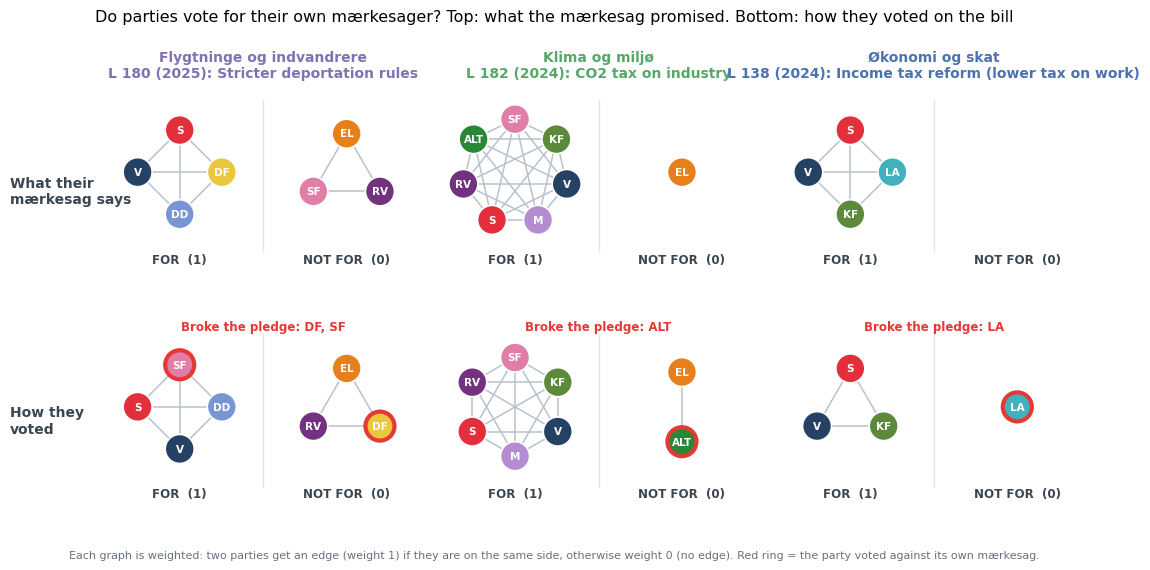

In [ ]:
# --- Holder de deres mærkesager? Top 3 mærkesager: promise network vs. vote network ---
# Two weighted graphs per mærkesag (week 1: weighted networks):
#   PROMISE graph: weight 1 between two parties if their mærkesager point the same way on the bill, else 0
#   VOTE graph:    weight 1 between two parties if they voted the same way (for = 1, not for = 0), else 0
# Only weight-1 edges are drawn, so each graph splits into a "for" group and an "against" group.
import re
import itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

MAPPE = "../../data/"      # notebook in notebooks/HolderDe/ – change if your notebook lies elsewhere
PARTIER = ["EL", "SF", "ALT", "RV", "S", "M", "V", "KF", "LA", "DD", "DF", "NB"]
FARVER = {"S": "#E32F3B", "V": "#254264", "M": "#B48CD2", "SF": "#E07EA8", "DD": "#7896D2", "LA": "#3FB2BE",
          "KF": "#5C8A3A", "EL": "#E6801A", "DF": "#EAC73E", "RV": "#733280", "ALT": "#2B8738"}

# 1 = the party's mærkesag supports what the bill does, 0 = the mærkesag is against it (from the mærkesag texts)
TOP3 = [
    {"maerkesag": "Flygtninge og indvandrere", "farve": "#8172B3", "afstemning_id": 10320,
     "lov": "L 180 (2025): Stricter deportation rules",
     "loefter": {"S": 1, "V": 1, "DF": 1, "DD": 1, "EL": 0, "SF": 0, "RV": 0}},
    {"maerkesag": "Klima og miljø", "farve": "#55A868", "afstemning_id": 9847,
     "lov": "L 182 (2024): CO2 tax on industry",
     "loefter": {"S": 1, "V": 1, "SF": 1, "RV": 1, "ALT": 1, "KF": 1, "M": 1, "EL": 0}},   # EL: wanted the rebate to big emitters cancelled
    {"maerkesag": "Økonomi og skat", "farve": "#4C72B0", "afstemning_id": 9656,
     "lov": "L 138 (2024): Income tax reform (lower tax on work)",
     "loefter": {"S": 1, "V": 1, "KF": 1, "LA": 1}},
]

# 2. How each party voted: Folketinget's official conclusion of the final vote
afst = pd.read_csv(MAPPE + "processed/afstemninger_2022_2026.csv", usecols=["afstemning_id", "konklusion"])
def partistemmer(tekst):
    tekst = re.sub(r"[A-ZÆØÅ][\wæøåé\.-]+(?: [A-ZÆØÅ][\wæøåé\.-]+)+ \([A-ZÆØÅ]+\)", "", str(tekst))  # drop single MPs
    dele = re.split(r"(?i)(for stemte|imod stemte|hverken for eller imod stemte)", tekst)
    ud = {}
    for etiket, indhold in zip(dele[1::2], dele[2::2]):
        for p in PARTIER:
            if re.search(rf"(?<!\w){p}(?!\w)", indhold):
                ud[p] = 1 if etiket.lower() == "for stemte" else 0      # for = 1, against/abstain = 0
    return ud
STEMMER = {i: partistemmer(k) for i, k in zip(afst["afstemning_id"], afst["konklusion"])}

def vaegtet_graf(vaerdi):
    """Weighted graph: weight 1 between two parties with the same value (both 1 or both 0), otherwise 0."""
    G = nx.Graph()
    G.add_nodes_from(vaerdi)
    for a, b in itertools.combinations(vaerdi, 2):
        G.add_edge(a, b, weight=int(vaerdi[a] == vaerdi[b]))
    return G

def placering(vaerdi):
    """'For' group on a small circle to the left, 'against' group to the right."""
    pos = {}
    for gruppe, cx in [(1, -1.15), (0, 1.15)]:
        medl = [p for p in PARTIER if vaerdi.get(p) == gruppe]
        for k, p in enumerate(medl):
            v = np.pi / 2 + 2 * np.pi * k / max(len(medl), 1)
            r = 0 if len(medl) == 1 else 0.38 + 0.05 * len(medl)
            pos[p] = (cx + r * np.cos(v), r * np.sin(v))
    return pos

def tegn(ax, G, pos, brudt=()):
    for a, b, d in G.edges(data=True):
        if d["weight"] == 1:
            ax.plot(*zip(pos[a], pos[b]), color="#b8c2cc", lw=1.1, zorder=1)
    for p in G.nodes:
        x, y = pos[p]
        ax.add_patch(Circle((x, y), 0.2, fc=FARVER[p], zorder=3,
                            ec="#e53935" if p in brudt else "white", lw=3 if p in brudt else 1.2))
        ax.text(x, y, p, ha="center", va="center", fontsize=7.5, fontweight="bold", color="white", zorder=4)
    ax.text(-1.15, -1.25, "FOR  (1)", ha="center", fontsize=8.5, fontweight="bold", color="#3c4650")
    ax.text(1.15, -1.25, "NOT FOR  (0)", ha="center", fontsize=8.5, fontweight="bold", color="#3c4650")
    ax.plot([0, 0], [-1.1, 1.0], color="#e3e7eb", lw=1, zorder=0)
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-1.45, 1.15); ax.set_aspect("equal"); ax.axis("off")

fig, akser = plt.subplots(2, 3, figsize=(11, 5.6))
for k, m in enumerate(TOP3):
    loefte = m["loefter"]
    stemt = {p: STEMMER[m["afstemning_id"]].get(p, 0) for p in loefte}        # same parties as in the promise graph
    brudt = [p for p in loefte if loefte[p] != stemt[p]]
    G_loefte, G_stemt = vaegtet_graf(loefte), vaegtet_graf(stemt)
    tegn(akser[0, k], G_loefte, placering(loefte))
    tegn(akser[1, k], G_stemt, placering(stemt), brudt)
    akser[0, k].set_title(f"{m['maerkesag']}\n{m['lov']}", fontsize=10, fontweight="bold", color=m["farve"], pad=8)
    akser[1, k].text(0, 1.05, ("Kept by all" if not brudt else "Broke the pledge: " + ", ".join(brudt)),
                     ha="center", fontsize=8.5, color="#2e7d32" if not brudt else "#e53935", fontweight="bold")
    print(f"{m['maerkesag']:26s} kept {len(loefte) - len(brudt)}/{len(loefte)} · broke: {brudt or '-'}")

fig.text(0.005, 0.66, "What their\nmærkesag says", fontsize=10, fontweight="bold", color="#3c4650", va="center")
fig.text(0.005, 0.25, "How they\nvoted", fontsize=10, fontweight="bold", color="#3c4650", va="center")
fig.text(0.5, 0.005, "Each graph is weighted: two parties get an edge (weight 1) if they are on the same side, otherwise weight 0 (no edge). "
         "Red ring = the party voted against its own mærkesag.", ha="center", fontsize=8, color="#66717d")
fig.subplots_adjust(left=0.09, right=0.99, top=0.88, bottom=0.05, wspace=0.05, hspace=0.02)
fig.suptitle("Do parties vote for their own mærkesager? Top: what the mærkesag promised. Bottom: how they voted on the bill",
             fontsize=11.5, x=0.5, y=0.985)
fig.savefig("fig3_top3_maerkesager.png", dpi=300, bbox_inches="tight")
plt.show()


3 love: 79% holdt (null 63%, p = 0.109) | 24 love: 86% (null 78%, p < 0.001) | S/V/M for 99%, opposition 72%–93%


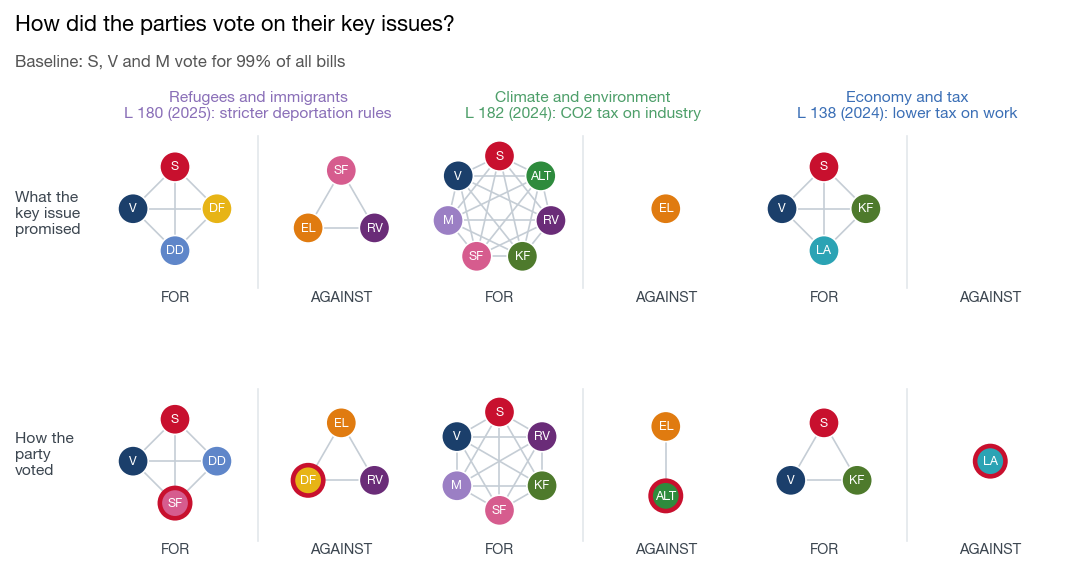

In [8]:
# --- FIGUR 3 · Holder partierne deres mærkesager? (ny stil + validering) ---
# Indsæt i mærkesager_vs_stemmer.ipynb (erstatter den gamle celle). Kræver stil.py i notebooks/.
import re, sys, itertools
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
sys.path.append("..")
from stil import *

DATA = "../../data/"

# 1. Hvordan stemte partierne? (Folketingets officielle konklusion; for = 1, imod/hverken = 0)
afst = pd.read_csv(DATA + "processed/afstemninger_2022_2026.csv")
afst["dato"] = afst["dato"].astype(str).str[:10]
afst = afst.set_index("afstemning_id")

def partistemmer(tekst):
    tekst = re.sub(r"[A-ZÆØÅ][\wæøåé\.-]+(?: [A-ZÆØÅ][\wæøåé\.-]+)+ \([A-ZÆØÅ]+\)", "", str(tekst))   # fjern enkelt-MF'ere
    dele = re.split(r"(?i)(for stemte|imod stemte|hverken for eller imod stemte)", tekst)
    ud = {}
    for etiket, indhold in zip(dele[1::2], dele[2::2]):
        for p in PARTIER:
            if re.search(rf"(?<!\w){p}(?!\w)", indhold):
                ud[p] = 1 if etiket.lower() == "for stemte" else 0
    return ud

STEMMER = {i: partistemmer(k) for i, k in afst["konklusion"].items()}
endelige = afst[(afst["afstemningstype"] == "Endelig vedtagelse") & (afst["sagstype"] == "Lovforslag")]
endelig_alle = afst[afst["afstemningstype"] == "Endelig vedtagelse"]
find_id = lambda sag, dato: next(iter(endelig_alle[(endelig_alle["sag_nummer"].str.strip() == sag) & (endelig_alle["dato"] == dato)].index), None)

# 2. Løfterne: 1 = mærkesagen er FOR lovens retning, 0 = IMOD (læst i mærkesagerne)
EMNER = [
    {"emne": "Refugees and immigrants", "farve": EMNE_FARVE["Refugees and immigrants"], "lov": ("L 180", "2025-06-04"),
     "titel": "L 180 (2025): stricter deportation rules",
     "loefter": {"S": 1, "V": 1, "DF": 1, "DD": 1, "EL": 0, "SF": 0, "RV": 0},
     "alle_love": [("L 56 B", "2024-12-17"), ("L 179", "2025-06-04"), ("L 180", "2025-06-04"), ("L 163", "2025-06-11"),
                   ("L 219 A", "2025-06-11"), ("L 4", "2025-11-20"), ("L 5", "2025-12-04"), ("L 14", "2026-08-27")]},
    {"emne": "Climate and environment", "farve": EMNE_FARVE["Climate and environment"], "lov": ("L 182", "2024-06-04"),
     "titel": "L 182 (2024): CO2 tax on industry",
     "loefter": {"S": 1, "V": 1, "SF": 1, "RV": 1, "ALT": 1, "KF": 1, "M": 1, "EL": 0},    # EL ville fjerne rabatten
     "el_paa_alle": 1,                                                                    # på klimalove generelt er EL for
     "alle_love": [("L 15 A", "2023-03-23"), ("L 47", "2023-04-20"), ("L 118", "2024-05-23"), ("L 182", "2024-06-04"),
                   ("L 183", "2024-06-04"), ("L 23", "2024-11-28"), ("L 17", "2024-12-03"), ("L 5", "2026-09-03")]},
    {"emne": "Economy and tax", "farve": EMNE_FARVE["Economy and tax"], "lov": ("L 138", "2024-05-16"),
     "titel": "L 138 (2024): lower tax on work",
     "loefter": {"S": 1, "V": 1, "KF": 1, "LA": 1},
     "alle_love": [("L 76 B", "2023-05-25"), ("L 93 B", "2024-01-30"), ("L 119 C", "2024-04-04"), ("L 138", "2024-05-16"),
                   ("L 132", "2024-06-04"), ("L 28", "2025-12-11"), ("L 1", "2026-06-25"), ("L 36 A", "2026-11-12")]},
]

# 3. VALIDERING (uge 2): bland stemmerne mellem partierne på hver lov (samme antal for/imod)
def holdt_og_null(par, n, seed=0):
    r = np.random.default_rng(seed)
    null = np.array([(par["loefte"] == par.groupby("aid")["stemte"].transform(lambda x: r.permutation(x.values))).mean() for _ in range(n)])
    return par["holdt"].mean(), null

tre, alle = [], []
for e in EMNER:
    aid = find_id(*e["lov"])
    tre += [{"aid": aid, "parti": p, "loefte": l, "stemte": STEMMER[aid].get(p, 0)} for p, l in e["loefter"].items()]
    loefter8 = dict(e["loefter"], **({"EL": e["el_paa_alle"]} if "el_paa_alle" in e else {}))
    for a in filter(None, (find_id(*l) for l in e["alle_love"])):
        alle += [{"emne": e["emne"], "aid": a, "parti": p, "loefte": l, "stemte": STEMMER[a][p]} for p, l in loefter8.items() if p in STEMMER[a]]
tre, alle = pd.DataFrame(tre), pd.DataFrame(alle)
tre["holdt"], alle["holdt"] = tre["loefte"] == tre["stemte"], alle["loefte"] == alle["stemte"]
h3, n3 = holdt_og_null(tre, 10000)
h24, n24 = holdt_og_null(alle, 2000)
p3, p24 = p_vaerdi(h3, n3), p_vaerdi(h24, n24)

# Baseline: hvor ofte stemmer hvert parti FOR på alle endelige lovforslag?
for_andel = {p: np.mean([STEMMER[i][p] for i in endelige.index if p in STEMMER[i]]) for p in PARTIER}
opp = [for_andel[p] for p in PARTIER if p not in REGERING]
print(f"3 love: {h3:.0%} holdt (null {n3.mean():.0%}, {p_tekst(p3)}) | 24 love: {h24:.0%} (null {n24.mean():.0%}, {p_tekst(p24)}) | "
      f"S/V/M for {min(for_andel[p] for p in REGERING):.0%}, opposition {min(opp):.0%}–{max(opp):.0%}")

# 4. Tegn
def vaegtet_graf(vaerdi):
    G = nx.Graph(); G.add_nodes_from(vaerdi)
    for a, b in itertools.combinations(vaerdi, 2):
        if vaerdi[a] == vaerdi[b]:
            G.add_edge(a, b)
    return G

def placering(vaerdi):
    pos = {}
    for gruppe, cx in [(1, -1.15), (0, 1.15)]:
        medl = [p for p in PARTIER if vaerdi.get(p) == gruppe]
        for k, p in enumerate(medl):
            v = np.pi / 2 + 2 * np.pi * k / max(len(medl), 1)
            r = 0 if len(medl) == 1 else 0.38 + 0.05 * len(medl)
            pos[p] = (cx + r * np.cos(v), r * np.sin(v))
    return pos

def tegn(ax, vaerdi, brudt=()):
    G, pos = vaegtet_graf(vaerdi), placering(vaerdi)
    for a, b in G.edges():
        ax.plot(*zip(pos[a], pos[b]), color="#c5cdd5", lw=0.8, zorder=1)
    for p in G.nodes:
        x, y = pos[p]
        ax.add_patch(Circle((x, y), 0.21, fc=PARTI_FARVE[p], zorder=3,
                            ec=ROED if p in brudt else "white", lw=2.2 if p in brudt else 0.8))
        ax.text(x, y, p, ha="center", va="center", fontsize=6, fontweight="bold", color="white", zorder=4)
    ax.text(-1.15, -1.28, "FOR", ha="center", fontsize=7, fontweight="bold", color=MOERK)
    ax.text(1.15, -1.28, "AGAINST", ha="center", fontsize=7, fontweight="bold", color=MOERK)
    ax.plot([0, 0], [-1.1, 1.0], color="#e3e7eb", lw=0.8, zorder=0)
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-1.45, 1.15); ax.set_aspect("equal"); ax.axis("off")

fig, akser = plt.subplots(2, 3, figsize=(BREDDE, 10.2 * CM))
for k, e in enumerate(EMNER):
    aid = find_id(*e["lov"])
    stemt = {p: STEMMER[aid].get(p, 0) for p in e["loefter"]}
    brudt = [p for p in e["loefter"] if e["loefter"][p] != stemt[p]]
    tegn(akser[0, k], e["loefter"])
    tegn(akser[1, k], stemt, brudt)
    akser[0, k].set_title(f"{e['emne']}\n{e['titel']}", fontsize=7.5, fontweight="bold", color=e["farve"], pad=4)

    d = alle[alle["emne"] == e["emne"]]
    brud8 = d.groupby("parti")["holdt"].apply(lambda x: int((~x).sum()))
    brud8 = brud8[brud8 > 0].sort_values(ascending=False)
    n_love = d["aid"].nunique()
    

fig.text(0.0, 0.70, "What the\nkey issue\npromised", fontsize=7.5, fontweight="bold", color=MOERK, va="center")
fig.text(0.0, 0.30, "How the\nparty\nvoted", fontsize=7.5, fontweight="bold", color=MOERK, va="center")
fig.subplots_adjust(left=0.08, right=1.0, top=0.88, bottom=0.08, wspace=0.02, hspace=0.1)
titel(fig, "How did the parties vote on their key issues?",
      f"Baseline: S, V and M vote for {min(for_andel[p] for p in REGERING):.0%} of all bills", y=0.93)
gem(fig, "fig3_loefter_vs_stemmer")                     # gemmer fig3_loefter_vs_stemmer.pdf + .png
import logging; logging.getLogger("fontTools").setLevel(logging.ERROR)
fig.savefig("fig3_final.pdf", bbox_inches="tight"); fig.savefig("fig3_final.png", dpi=300, bbox_inches="tight")
plt.show()
